# Clean good frames (newest QC) vs the other EODs: distance between the fish, and where the fish are

EOD tables: `*_synch_fix_newest.csv` only (2-fish 2024-02-13, 3-fish 2024-10-15). Each EOD's video frame is the newest table's
`Frame`. **Clean good** = that frame passes the mask QC, Denis' SLEAP-good rule and the 0.8 × median mask-length limit
(`clean_good_frames_newest.py`); **other** = every other EOD. Geometry from the ZEUS masks of the EOD's frame
(`frame_geometry_newest.py`):
- **distance to the nearest fish**: from the emitter (2-fish: fish 1, 3-fish: fish 0) to the nearest other fish, mask edge to edge
  (closest pair of mask pixels, cm). The mask QC itself drops frames where two masks come within 5 px (0.33 cm), so clean frames
  cannot have touching fish;
- **position**: centroid of each fish's mask (cm from the top-left corner of the video; 912 px = 60 cm).

An EOD whose frame lacks a mask of some fish has no distance (counted separately), and that fish has no position.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import mannwhitneyu, ks_2samp
from eod_assign import load_electrode_pairs

PX_PER_CM, P = 912 / 60, 912
OUT = 'results/newest_qc'; import os; os.makedirs(OUT, exist_ok=True)
REC = {
    '2-fish': dict(res='results/eod_ground_truth', fish=(0, 1), emitter=1, label='2-fish (2024-02-13)',
                   names={1: 'fish 1 (emitter, larger)', 0: 'fish 0 (silent, smaller)'},
                   electrodes='data/electrodes/electrodes_signed_px_coord_2-fish.csv'),
    '3-fish': dict(res='results/eod_ground_truth_3fish', fish=(0, 1, 2), emitter=0, label='3-fish (2024-10-15)',
                   names={0: 'fish 0 (emitter, smallest)', 1: 'fish 1 (silent, largest)', 2: 'fish 2 (silent, middle)'},
                   electrodes='data/electrodes/electrodes_signed_px_coord_3-fish.csv'),
}
GROUP_COL = {'clean good': '#1F5FBF', 'other': '#E8710A'}
G = {}
for name, c in REC.items():
    g = pd.read_csv(f"{c['res']}/eod_geometry_synch_fix_newest.csv"); g['group'] = np.where(g.clean_good, 'clean good', 'other'); G[name] = g
    el = load_electrode_pairs(c['electrodes'], P)
    c['el'] = [(pid, np.asarray(a) * (P - 1) / PX_PER_CM, np.asarray(b) * (P - 1) / PX_PER_CM) for pid, a, b in el]   # (row, col) cm
    n = g.group.value_counts()
    print(f"{c['label']}: {len(g)} EODs: clean good {n['clean good']}, other {n['other']}; "
          f"no distance (a fish without mask): clean {g.gap_emitter_cm[g.clean_good].isna().sum()}, other {g.gap_emitter_cm[~g.clean_good].isna().sum()}")

2-fish (2024-02-13): 18801 EODs: clean good 3536, other 15265; no distance (a fish without mask): clean 0, other 160
3-fish (2024-10-15): 19796 EODs: clean good 6764, other 13032; no distance (a fish without mask): clean 0, other 48


## Distance from the emitter to the nearest other fish

2-fish (2024-02-13): Mann-Whitney p = 0.0e+00, KS D = 0.336
3-fish (2024-10-15): Mann-Whitney p = 1.5e-43, KS D = 0.178
          recording      group     n  median_cm   q25   q75  pct_below_2cm  pct_below_5cm  pct_below_10cm
2-fish (2024-02-13) clean good  3536      35.68 14.82 42.77           3.00          10.27           19.99
2-fish (2024-02-13)      other 15105      12.93  0.74 31.34          30.65          38.40           46.45
3-fish (2024-10-15) clean good  6764      11.76  6.56 16.47           6.67          19.47           40.91
3-fish (2024-10-15)      other 12984       9.30  2.30 18.23          23.64          35.14           52.21


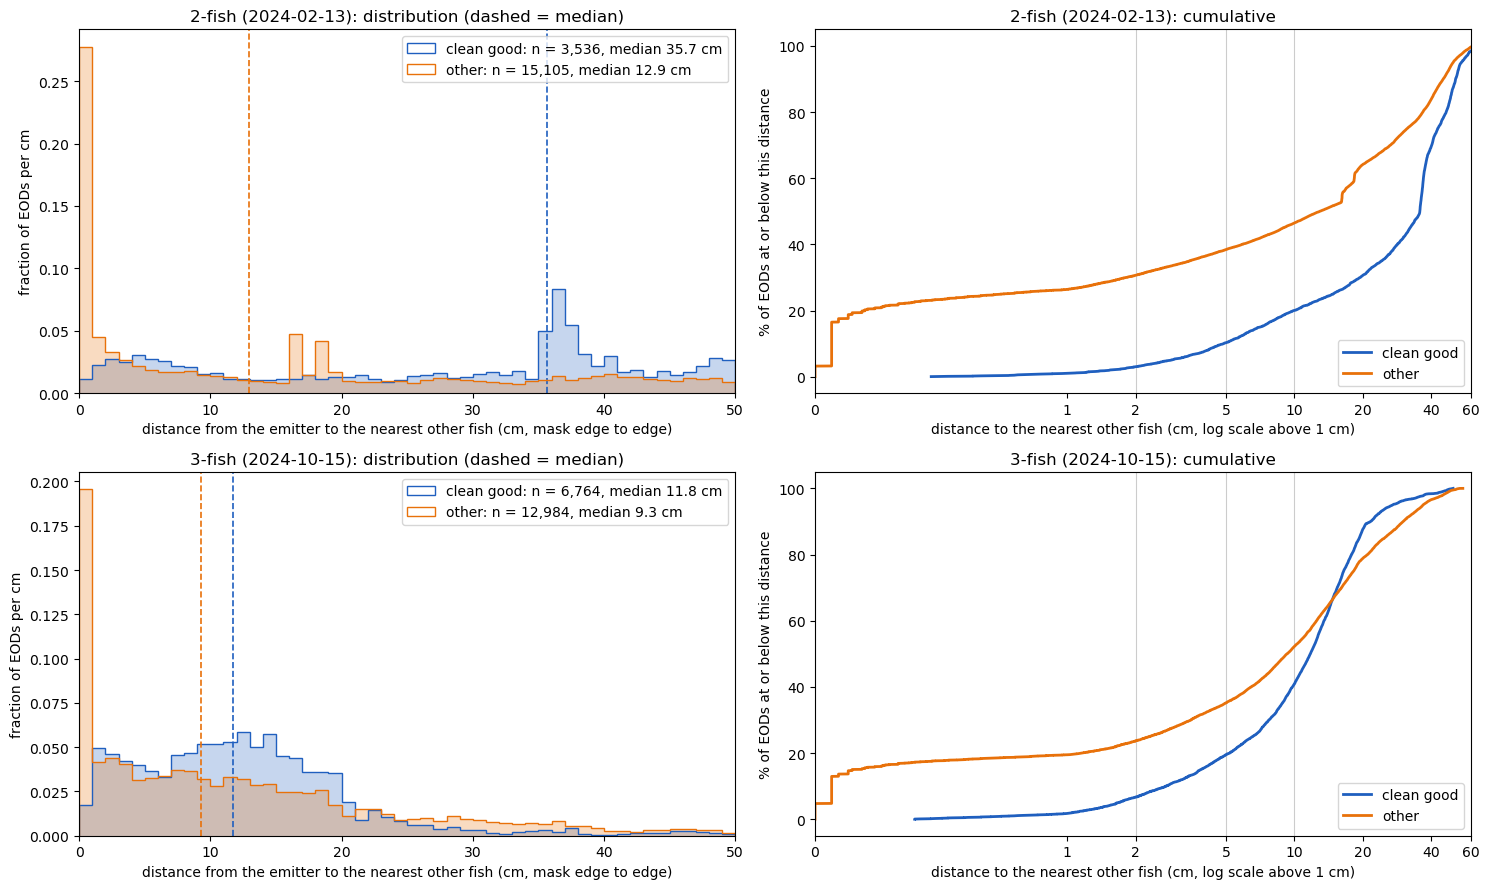

In [2]:
rows = []
for name, c in REC.items():
    g = G[name]; a, b = (g.gap_emitter_cm[g.group == k].dropna().to_numpy() for k in ('clean good', 'other'))
    for k, v in (('clean good', a), ('other', b)):
        rows.append(dict(recording=c['label'], group=k, n=len(v), median_cm=np.median(v), q25=np.percentile(v, 25), q75=np.percentile(v, 75),
                         pct_below_2cm=100 * (v < 2).mean(), pct_below_5cm=100 * (v < 5).mean(), pct_below_10cm=100 * (v < 10).mean()))
    print(f"{c['label']}: Mann-Whitney p = {mannwhitneyu(a, b).pvalue:.1e}, KS D = {ks_2samp(a, b).statistic:.3f}")
DIST = pd.DataFrame(rows); print(DIST.to_string(index=False, float_format=lambda v: f'{v:.2f}'))
DIST.to_csv(f'{OUT}/nearest_fish_distance_clean_vs_other.csv', index=False)

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
bins = np.arange(0, 50.5, 1)
for row, (name, c) in enumerate(REC.items()):
    g = G[name]; A, B = ax[row, 0], ax[row, 1]
    for k, col in GROUP_COL.items():
        v = g.gap_emitter_cm[g.group == k].dropna().to_numpy(); med = np.median(v)
        A.hist(v, bins, density=True, histtype='stepfilled', alpha=0.25, color=col)
        A.hist(v, bins, density=True, histtype='step', lw=2, color=col, label=f'{k}: n = {len(v):,}, median {med:.1f} cm')
        A.axvline(med, color=col, ls='--', lw=1.2)
        x = np.sort(v); B.plot(x, np.arange(1, len(x) + 1) / len(x) * 100, color=col, lw=2, label=k)
    A.set_xlabel('distance from the emitter to the nearest other fish (cm, mask edge to edge)'); A.set_ylabel('fraction of EODs per cm')
    A.set_title(f"{c['label']}: distribution (dashed = median)"); A.legend(); A.set_xlim(0, 50)
    for t in (2, 5, 10): B.axvline(t, color='0.8', lw=0.8, zorder=0)
    B.set_xscale('symlog', linthresh=1); B.set_xlim(0, 60); B.set_xticks([0, 1, 2, 5, 10, 20, 40, 60], ['0', '1', '2', '5', '10', '20', '40', '60'])
    B.set_xlabel('distance to the nearest other fish (cm, log scale above 1 cm)'); B.set_ylabel('% of EODs at or below this distance')
    B.set_title(f"{c['label']}: cumulative"); B.legend(loc='lower right')
fig.tight_layout(); fig.savefig(f'{OUT}/nearest_fish_distance_clean_vs_other.png', dpi=100, bbox_inches='tight'); plt.show()

## Where the fish are: clean good vs other EODs, per fish

2D histogram of each fish's mask centroid (2 cm squares), as % of that group's EODs with a mask of the fish. Left: clean good;
middle: other; right: difference (clean − other, percentage points; blue = over-represented in clean good frames; colour clipped at the 99th percentile of |difference|, since a few squares where a fish sat still for many EODs would otherwise set the scale). Electrodes:
+ pole filled, − pole open, numbered by pair.

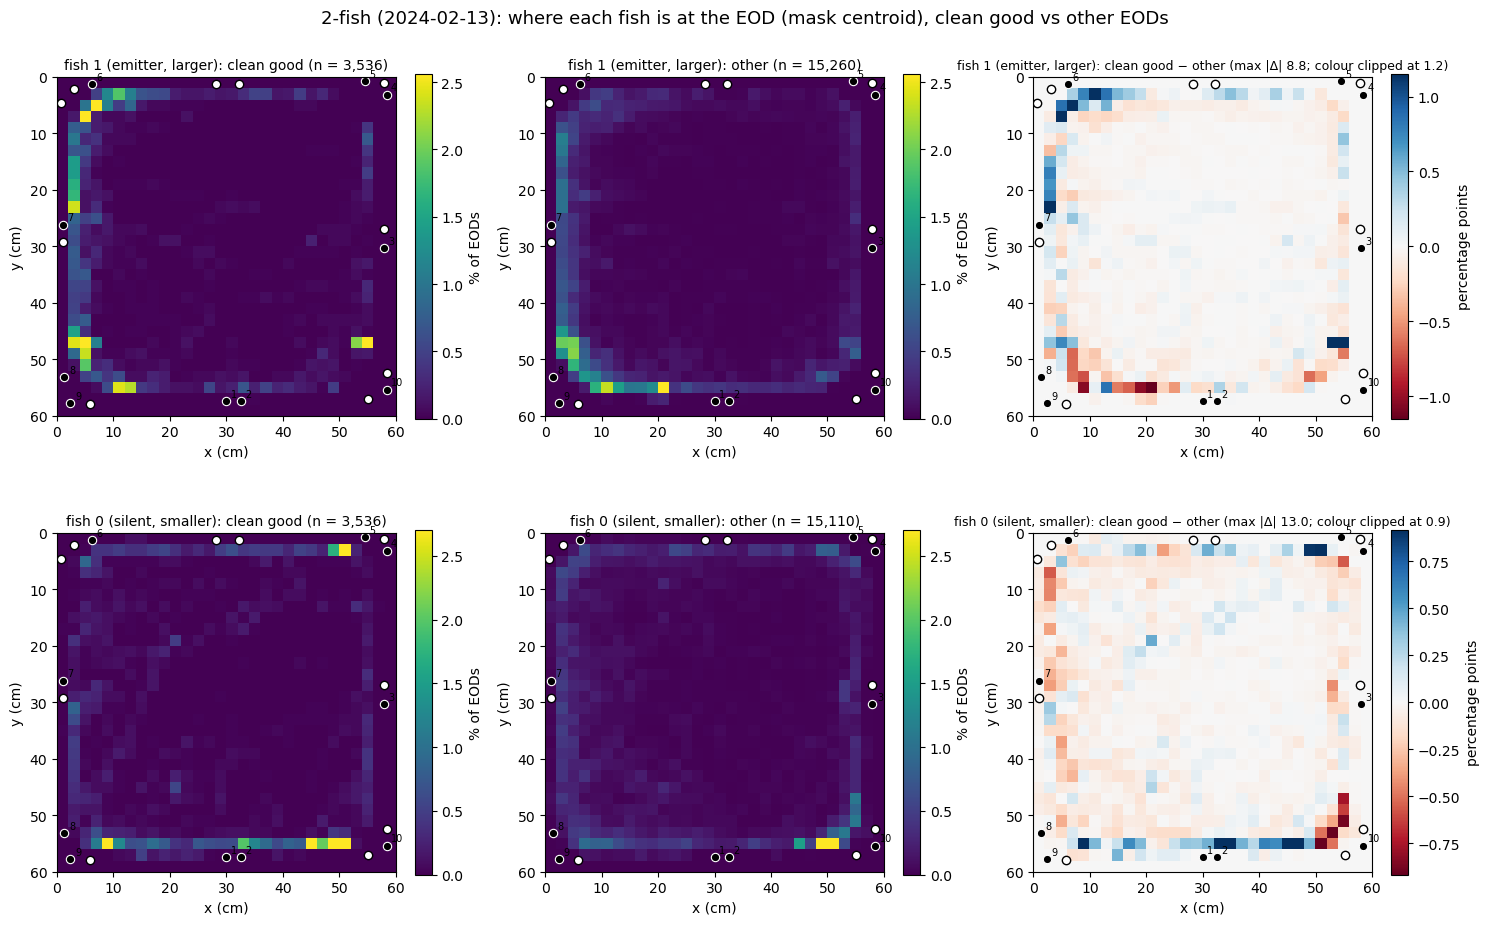

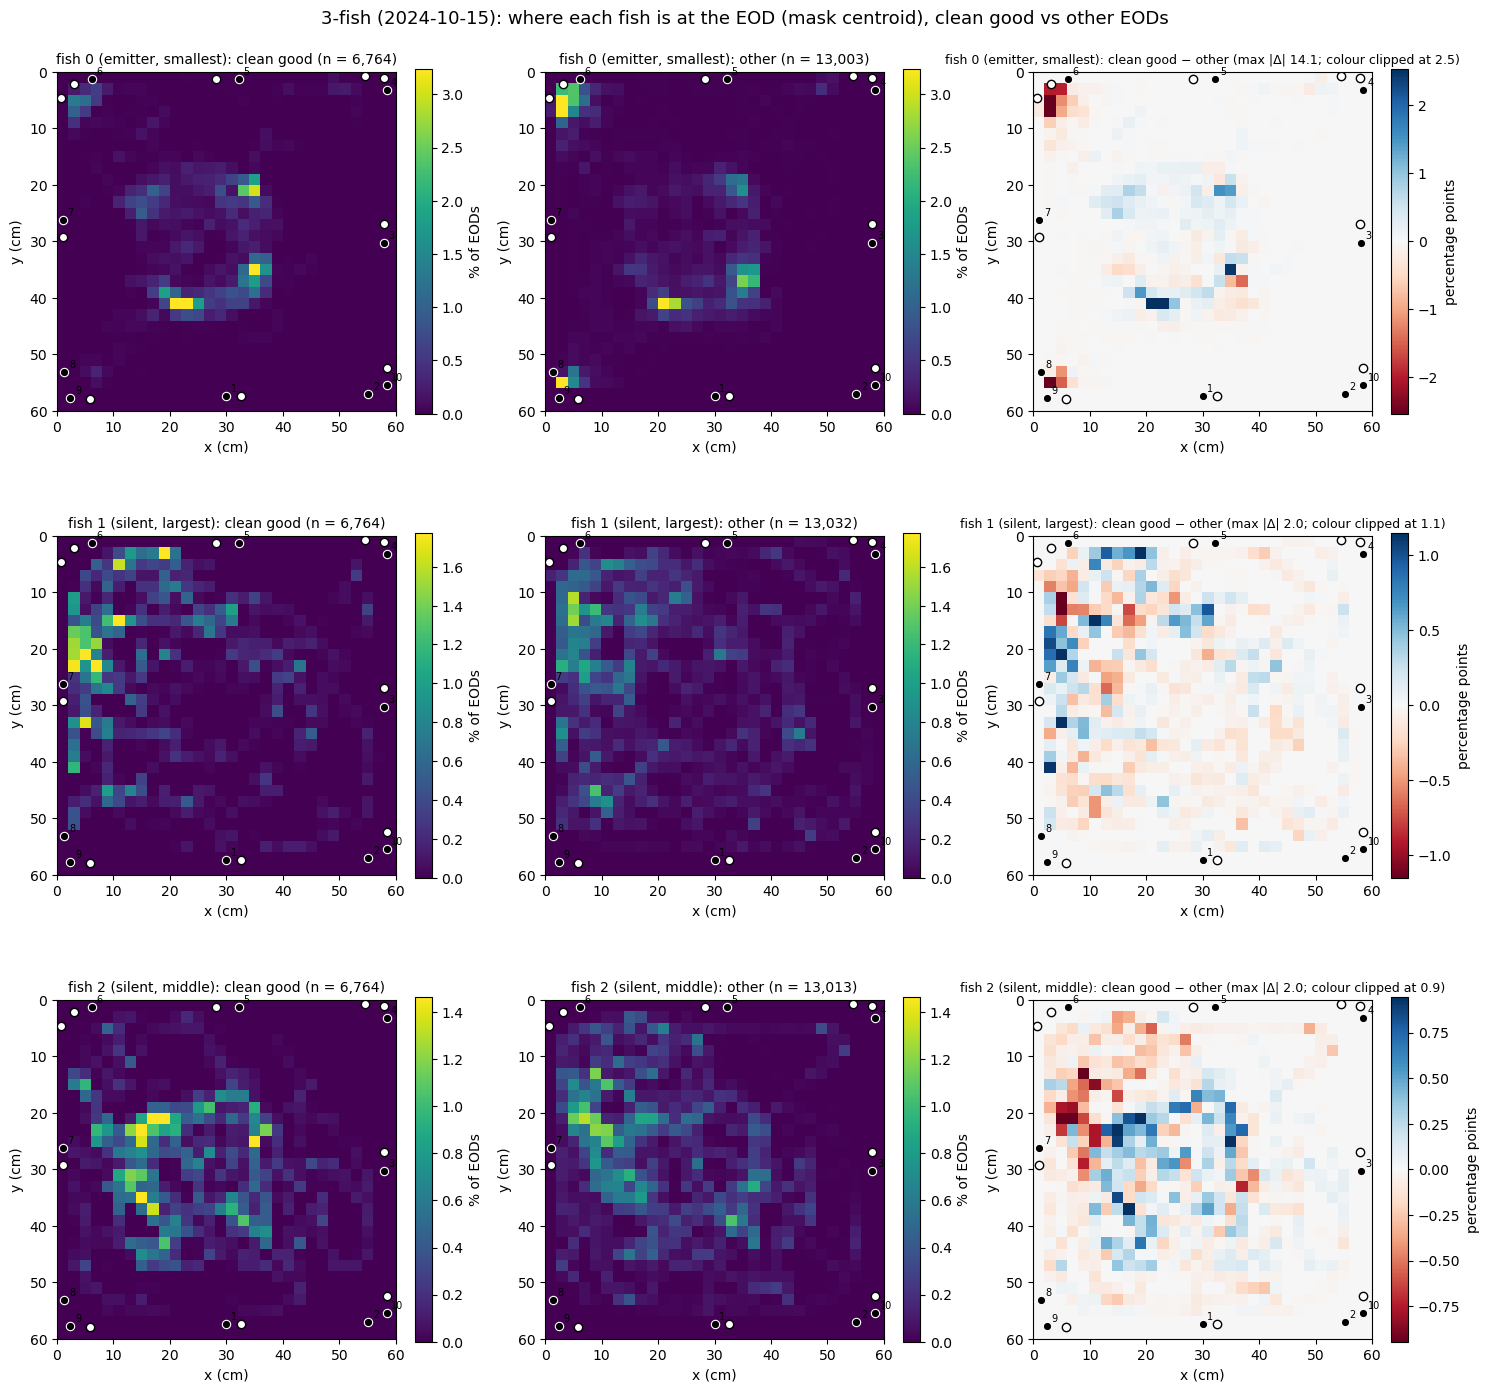

In [3]:
EDGES = np.arange(0, 60.01, 2)
def occupancy(x, y):
    h, _, _ = np.histogram2d(y, x, [EDGES, EDGES]); return 100 * h / max(len(x), 1)

def draw_electrodes(a, el):
    for pid, plus, minus in el:
        a.plot(plus[1], plus[0], 'o', ms=6, mfc='k', mec='w', mew=0.8); a.plot(minus[1], minus[0], 'o', ms=6, mfc='w', mec='k', mew=1)
        a.text(plus[1] + 0.8, plus[0] - 0.8, str(pid), fontsize=7, color='k')

for name, c in REC.items():
    g = G[name]; nf = len(c['fish'])
    fig, ax = plt.subplots(nf, 3, figsize=(15, 4.8 * nf), squeeze=False)
    for r, f in enumerate([c['emitter']] + [f for f in c['fish'] if f != c['emitter']]):
        H = {}
        for k in ('clean good', 'other'):
            s = g[(g.group == k) & g[f'x_{f}'].notna()]; H[k] = (occupancy(s[f'x_{f}'], s[f'y_{f}']), len(s))
        vmax = max(np.percentile(H[k][0][H[k][0] > 0], 99) for k in H)
        for j, k in enumerate(('clean good', 'other')):
            im = ax[r, j].imshow(H[k][0], extent=[0, 60, 60, 0], cmap='viridis', vmin=0, vmax=vmax, interpolation='nearest')
            ax[r, j].set_title(f"{c['names'][f]}: {k} (n = {H[k][1]:,})", fontsize=10)
            fig.colorbar(im, ax=ax[r, j], fraction=0.046, label='% of EODs')
        D = H['clean good'][0] - H['other'][0]; lim = np.percentile(np.abs(D[D != 0]), 99)   # a few squares where a fish sat still saturate
        im = ax[r, 2].imshow(D, extent=[0, 60, 60, 0], cmap='RdBu', norm=TwoSlopeNorm(0, -lim, lim), interpolation='nearest')
        ax[r, 2].set_title(f"{c['names'][f]}: clean good − other (max |Δ| {np.abs(D).max():.1f}; colour clipped at {lim:.1f})", fontsize=9); fig.colorbar(im, ax=ax[r, 2], fraction=0.046, label='percentage points')
        for a in ax[r]:
            draw_electrodes(a, c['el']); a.set_xlim(0, 60); a.set_ylim(60, 0); a.set_aspect('equal'); a.set_xlabel('x (cm)'); a.set_ylabel('y (cm)')
    fig.suptitle(f"{c['label']}: where each fish is at the EOD (mask centroid), clean good vs other EODs", fontsize=13)
    fig.tight_layout(); fig.savefig(f"{OUT}/fish_position_clean_vs_other_{name}.png", dpi=90, bbox_inches='tight'); plt.show()

## Summary per fish: distance to the nearest wall and to the tank centre

In [4]:
rows = []
for name, c in REC.items():
    g = G[name]
    for f in c['fish']:
        for k in ('clean good', 'other'):
            s = g[(g.group == k) & g[f'x_{f}'].notna()]; x, y = s[f'x_{f}'].to_numpy(), s[f'y_{f}'].to_numpy()
            wall = np.minimum.reduce([x, y, 60 - x, 60 - y]); centre = np.hypot(x - 30, y - 30)
            rows.append(dict(recording=c['label'], fish=c['names'][f], group=k, n=len(s), median_wall_cm=np.median(wall),
                             pct_within_5cm_of_wall=100 * (wall < 5).mean(), median_centre_cm=np.median(centre)))
POS = pd.DataFrame(rows); print(POS.to_string(index=False, float_format=lambda v: f'{v:.1f}'))
POS.to_csv(f'{OUT}/fish_position_clean_vs_other_summary.csv', index=False)

          recording                       fish      group     n  median_wall_cm  pct_within_5cm_of_wall  median_centre_cm
2-fish (2024-02-13)   fish 0 (silent, smaller) clean good  3536             4.6                    62.7              29.7
2-fish (2024-02-13)   fish 0 (silent, smaller)      other 15110             5.1                    44.6              28.7
2-fish (2024-02-13)   fish 1 (emitter, larger) clean good  3536             4.8                    55.7              29.7
2-fish (2024-02-13)   fish 1 (emitter, larger)      other 15260             5.0                    50.1              28.3
3-fish (2024-10-15) fish 0 (emitter, smallest) clean good  6764            19.4                     7.6              13.1
3-fish (2024-10-15) fish 0 (emitter, smallest)      other 13003            16.7                    37.2              15.1
3-fish (2024-10-15)   fish 1 (silent, largest) clean good  6764             8.1                    30.1              24.7
3-fish (2024-10-15)   fi